# Preprocessing — Fashion Product Images

Notebook ini adalah versi **step-by-step** dari `02_prepare_fashion.py`.
Jalankan setelah `eda.ipynb` (butuh `data/processed/fashion_dhash.csv`).

| Step | Isi |
|---|---|
| 0 | Setup, import, konstanta |
| 1 | Fungsi helper (`tone_of`, `stratified_split`, `ids_signature`) |
| 2 | Muat label & folder output |
| 3 | Baca `styles.csv` & bersihkan baris inti |
| 4 | Buang duplikat persis (dHash) |
| 5 | Petakan label & turunkan atribut (weather/formality/tone) |
| 6 | Cap kelas `other` |
| 7 | Split stratified 80/10/10 |
| 8 | Cache gambar 128×128 (`fashion_128.npy`) |
| 9 | Tulis indeks & file split |
| 10 | Simpan laporan preprocessing |

> Set environment `FORCE_REBUILD=1` sebelum menjalankan untuk membuat ulang cache.

## Step 0 — Setup, import & konstanta

In [1]:
# Bootstrap: pastikan working directory = folder ml/ (pengganti Path(__file__))
import os
import sys
from pathlib import Path

ML_DIR = Path.cwd()
if not (ML_DIR / "config_utils.py").exists() and (ML_DIR / "ml" / "config_utils.py").exists():
    ML_DIR = ML_DIR / "ml"
os.chdir(ML_DIR)
sys.path.insert(0, str(ML_DIR))
print("working dir:", ML_DIR)

working dir: C:\NEURFIT_PROJECT\ml


In [2]:
import hashlib
import json

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import config_utils as cu
from preprocess import preprocess_path

IMG_SIZE = 128
SEED = 42
OTHER_MAX = 4000
EXCLUDE_GENDER = ("Boys", "Girls")

SEASON_WEATHER = {
    "Summer": "hot",
    "Spring": "mild",
    "Fall": "mild",
    "Winter": "cold",
}
USAGE_FORMALITY = {
    "formal": "formal",
    "smart_casual": "semi_formal",
    "party": "semi_formal",
    "casual": "non_formal",
    "sports": "non_formal",
}
WARM = {"red", "orange", "yellow", "brown", "beige", "pink"}
COOL = {"blue", "navy_blue", "green", "purple"}

## Step 1 — Fungsi helper

In [3]:
def tone_of(colour: str) -> str:
    if colour in WARM:
        return "warm"
    if colour in COOL:
        return "cool"
    return "neutral"


def stratified_split(
    df: pd.DataFrame,
    *,
    val_frac: float = 0.1,
    test_frac: float = 0.1,
    seed: int = SEED,
    stratify_col: str = "article_type",
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for _, group in df.groupby(stratify_col, sort=True):
        idx = group.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        if n < 3:
            tr.extend(idx.tolist())
            continue
        n_val = max(1, int(round(val_frac * n)))
        n_test = max(1, int(round(test_frac * n)))
        if n - n_val - n_test < 1:
            n_val, n_test = 0, 0
        va.extend(idx[:n_val].tolist())
        te.extend(idx[n_val:n_val + n_test].tolist())
        tr.extend(idx[n_val + n_test:].tolist())
    out = df.copy()
    out["split"] = "train"
    out.loc[va, "split"] = "val"
    out.loc[te, "split"] = "test"
    return out


def ids_signature(ids: pd.Series) -> str:
    joined = ",".join(str(int(i)) for i in ids.tolist())
    return hashlib.sha256(joined.encode("utf-8")).hexdigest()

## Step 2 — Muat label, mapping & folder output

In [4]:
labels = cu.load_labels()
processed = cu.ensure_dir(cu.fashion_processed_dir())
splits_dir = cu.ensure_dir(processed / "splits")
artifact_dir = cu.ensure_dir(cu.artifact_dir())

article_map = {
    e["dataset"]: e["key"]
    for e in labels["article_type"]
    if e.get("dataset")
}
colour_map = {
    ds: e["key"] for e in labels["base_colour"] for ds in e["dataset"]
}
usage_map = {
    ds: e["key"] for e in labels["usage"] for ds in e["dataset"]
}
print(f"article map: {len(article_map)} | colour map: {len(colour_map)} | usage map: {len(usage_map)}")

article map: 23 | colour map: 42 | usage map: 6


## Step 3 — Baca `styles.csv` & bersihkan baris inti

Buang id tidak valid, artikel/warna kosong, gender anak-anak, dan baris tanpa gambar.

In [5]:
raw = cu.fashion_raw_dir()
styles = pd.read_csv(raw / "styles.csv", on_bad_lines="skip")
cols = ["id", "gender", "articleType", "baseColour", "usage", "season"]
out = styles[cols].copy()
stats: dict[str, int] = {}

out["id"] = pd.to_numeric(out["id"], errors="coerce")
before = len(out)
out = out[out["id"].notna()].copy()
out["id"] = out["id"].astype("int64")
stats["drop_bad_id"] = before - len(out)

before = len(out)
out = out[out["articleType"].notna() & out["baseColour"].notna()].copy()
stats["drop_missing_core"] = before - len(out)

before = len(out)
out = out[~out["gender"].isin(list(EXCLUDE_GENDER))].copy()
stats["drop_gender"] = before - len(out)

images_dir = raw / "images"
before = len(out)
out = out[[(images_dir / f"{int(i)}.jpg").exists() for i in out["id"]]].copy()
stats["drop_missing_image"] = before - len(out)
print(stats, "| rows:", len(out))

{'drop_bad_id': 0, 'drop_missing_core': 15, 'drop_gender': 1485, 'drop_missing_image': 5} | rows: 42919


## Step 4 — Buang duplikat persis (dHash dari EDA)

In [6]:
dhash_path = processed / "fashion_dhash.csv"
if dhash_path.exists():
    hashes = pd.read_csv(dhash_path)
    hashes["id"] = hashes["id"].astype("int64")
    out = out.merge(hashes, on="id", how="left")
else:
    out["dhash"] = None

before = len(out)
out = out.drop_duplicates(subset=["dhash"], keep="first").copy()
stats["drop_exact_duplicate"] = before - len(out)
print("drop_exact_duplicate:", stats["drop_exact_duplicate"], "| rows:", len(out))

drop_exact_duplicate: 2468 | rows: 40451


## Step 5 — Petakan label & turunkan atribut

- `article_type` tak terpetakan → `other`
- `usage` tidak valid tetap disimpan tetapi di-mask (`usage_valid=False`)
- `weather` dari `season`, `formality` dari `usage`, `tone` dari warna

In [7]:
out["article_type"] = out["articleType"].map(article_map)
out["is_other"] = out["article_type"].isna()
out.loc[out["is_other"], "article_type"] = "other"

out["base_colour"] = out["baseColour"].map(colour_map)
before = len(out)
out = out[out["base_colour"].notna()].copy()
stats["drop_unmapped_colour"] = before - len(out)

out["usage"] = out["usage"].map(usage_map)
out["usage_valid"] = out["usage"].notna()
stats["usage_masked"] = int((~out["usage_valid"]).sum())

out["weather"] = out["season"].map(SEASON_WEATHER)
out["weather_valid"] = out["weather"].notna()
stats["weather_masked"] = int((~out["weather_valid"]).sum())

out["formality"] = out["usage"].map(USAGE_FORMALITY)
out["formality_valid"] = out["formality"].notna()
stats["formality_masked"] = int((~out["formality_valid"]).sum())

out["tone"] = out["base_colour"].map(tone_of)
print({k: stats[k] for k in ("drop_unmapped_colour", "usage_masked", "weather_masked", "formality_masked")})

{'drop_unmapped_colour': 205, 'usage_masked': 3314, 'weather_masked': 21, 'formality_masked': 3314}


## Step 6 — Cap kelas `other` (maks 4.000)

In [8]:
other = out[out["is_other"]]
stats["other_before_cap"] = int(len(other))
if len(other) > OTHER_MAX:
    keep = other.sample(n=OTHER_MAX, random_state=SEED)
    out = pd.concat([out[~out["is_other"]], keep]).sort_index()
stats["other_after_cap"] = int(out["is_other"].sum())
print("other before/after cap:", stats["other_before_cap"], stats["other_after_cap"])

other before/after cap: 11805 4000


## Step 7 — Split stratified 80/10/10 per `article_type`

In [9]:
out = out.sort_values("id").reset_index(drop=True)
out["image_path"] = [images_dir / f"{int(i)}.jpg" for i in out["id"]]

out = stratified_split(out, seed=SEED)
out = out.sort_values("id").reset_index(drop=True)
stats["rows_kept"] = int(len(out))
print("rows kept:", stats["rows_kept"])
print(out["split"].value_counts().to_dict())

rows kept: 32441
{'train': 25955, 'test': 3243, 'val': 3243}


## Step 8 — Cache gambar 128×128

Memakai `preprocess_path` (kontrak yang sama dengan backend). Cache dipakai ulang bila *signature* cocok.

In [10]:
npy_path = processed / f"fashion_{IMG_SIZE}.npy"
sig_path = processed / f"fashion_{IMG_SIZE}.signature.json"
signature = {
    "img_size": IMG_SIZE,
    "labels_version": labels.get("version"),
    "n": int(len(out)),
    "ids_sha256": ids_signature(out["id"]),
    "failures": 0,
}
reuse = False
if npy_path.exists() and sig_path.exists() and not os.environ.get("FORCE_REBUILD"):
    try:
        previous = json.loads(sig_path.read_text(encoding="utf-8"))
        reuse = previous == signature
    except Exception:
        reuse = False
print("signature:", signature)
print("reuse cache:", reuse)

signature: {'img_size': 128, 'labels_version': 'labels-v1', 'n': 32441, 'ids_sha256': '07aec2f0720299931b5db7f25af1aeed95dcb60e8233a83ad01796906bbe8a48', 'failures': 0}
reuse cache: True


In [11]:
if reuse:
    print("cache found and signature matches; reusing", npy_path)
else:
    arr = np.lib.format.open_memmap(
        npy_path, mode="w+", dtype=np.uint8,
        shape=(len(out), IMG_SIZE, IMG_SIZE, 3),
    )
    kept: list[int] = []
    failures: list[dict] = []
    write = 0
    for pos, row in enumerate(
        tqdm(out.itertuples(index=False), total=len(out), desc="cache 128px")
    ):
        try:
            image = preprocess_path(row.image_path, size=IMG_SIZE)
        except Exception as exc:
            failures.append({"id": int(row.id), "error": str(exc)})
            continue
        arr[write] = image
        kept.append(pos)
        write += 1
    arr.flush()
    del arr
    if write < len(out):
        src = np.load(npy_path, mmap_mode="r")
        tmp = npy_path.with_name(npy_path.stem + "_compact.npy")
        dst = np.lib.format.open_memmap(
            tmp, mode="w+", dtype=np.uint8,
            shape=(write, IMG_SIZE, IMG_SIZE, 3),
        )
        for start in range(0, write, 1024):
            dst[start:start + 1024] = src[start:start + 1024]
        dst.flush()
        del dst, src
        os.replace(tmp, npy_path)
    out = out.iloc[kept].reset_index(drop=True)
    signature["n"] = int(len(out))
    signature["ids_sha256"] = ids_signature(out["id"])
    signature["failures"] = len(failures)
    sig_path.write_text(json.dumps(signature, indent=2), encoding="utf-8")
    print(f"cache built: {len(out)} rows | failures: {len(failures)}")
if not sig_path.exists():
    sig_path.write_text(json.dumps(signature, indent=2), encoding="utf-8")

cache found and signature matches; reusing C:\NEURFIT_PROJECT\ml\data\processed\fashion_128.npy


## Step 9 — Tulis indeks & file split

In [12]:
index_df = out[[
    "id", "gender", "article_type", "base_colour", "usage", "usage_valid",
    "season", "weather", "weather_valid", "formality", "formality_valid",
    "tone", "is_other", "split",
]].copy()
index_df.insert(0, "npy_index", np.arange(len(index_df), dtype=np.int64))
index_df["usage"] = index_df["usage"].fillna("")
index_df["weather"] = index_df["weather"].fillna("")
index_df["formality"] = index_df["formality"].fillna("")
index_df["season"] = index_df["season"].fillna("")
def rel_posix(path: Path) -> str:
    try:
        return Path(path).resolve().relative_to(cu.data_dir()).as_posix()
    except ValueError:
        return Path(path).as_posix()

index_df["image_path"] = [rel_posix(p) for p in out["image_path"]]
index_df.to_csv(processed / "fashion_index.csv", index=False)
for split in ("train", "val", "test"):
    index_df[index_df["split"] == split].to_csv(
        splits_dir / f"{split}.csv", index=False
    )
index_df.head()

,npy_index,id,gender,article_type,base_colour,usage,usage_valid,season,weather,weather_valid,formality,formality_valid,tone,is_other,split,image_path
0,0,1163,Men,tshirt,blue,sports,True,Summer,hot,True,non_formal,True,cool,False,train,C:/NEURFIT_PROJECT/ml/data/fashionProduct/imag...
1,1,1164,Men,tshirt,blue,sports,True,Winter,cold,True,non_formal,True,cool,False,test,C:/NEURFIT_PROJECT/ml/data/fashionProduct/imag...
2,2,1165,Men,tshirt,blue,sports,True,Summer,hot,True,non_formal,True,cool,False,train,C:/NEURFIT_PROJECT/ml/data/fashionProduct/imag...
3,3,1525,Unisex,backpack,navy_blue,casual,True,Fall,mild,True,non_formal,True,cool,False,train,C:/NEURFIT_PROJECT/ml/data/fashionProduct/imag...
4,4,1526,Unisex,backpack,black,sports,True,Fall,mild,True,non_formal,True,neutral,False,train,C:/NEURFIT_PROJECT/ml/data/fashionProduct/imag...


## Step 10 — Simpan laporan preprocessing

In [13]:
report = {
    "labels_version": labels.get("version"),
    "seed": SEED,
    "img_size": IMG_SIZE,
    "clean_stats": stats,
    "rows_final": int(len(index_df)),
    "reused_cache": bool(reuse),
    "split_sizes": {
        str(k): int(v) for k, v in index_df["split"].value_counts().items()
    },
    "article_counts": {
        str(k): int(v) for k, v in index_df["article_type"].value_counts().items()
    },
    "colour_counts": {
        str(k): int(v) for k, v in index_df["base_colour"].value_counts().items()
    },
    "usage_counts": {
        str(k): int(v)
        for k, v in index_df["usage"].replace("", "<masked>").value_counts().items()
    },
    "weather_counts": {
        str(k): int(v)
        for k, v in index_df["weather"].replace("", "<masked>").value_counts().items()
    },
    "formality_counts": {
        str(k): int(v)
        for k, v in index_df["formality"].replace("", "<masked>").value_counts().items()
    },
    "tone_counts": {
        str(k): int(v) for k, v in index_df["tone"].value_counts().items()
    },
    "npy": {
        "path": cu.to_posix(npy_path),
        "shape": list(np.load(npy_path, mmap_mode="r").shape),
    },
}
(artifact_dir / "fashion_prepare_report.json").write_text(
    json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps({
    "rows": report["rows_final"],
    "split": report["split_sizes"],
    "weather": report["weather_counts"],
    "formality": report["formality_counts"],
    "stats": stats,
}, indent=2))
print("written:", cu.to_posix(processed / "fashion_index.csv"))

{
  "rows": 32441,
  "split": {
    "train": 25955,
    "test": 3243,
    "val": 3243
  },
  "weather": {
    "hot": 15196,
    "mild": 10114,
    "cold": 7110,
    "<masked>": 21
  },
  "formality": {
    "non_formal": 29423,
    "formal": 1738,
    "<masked>": 1206,
    "semi_formal": 74
  },
  "stats": {
    "drop_bad_id": 0,
    "drop_missing_core": 15,
    "drop_gender": 1485,
    "drop_missing_image": 5,
    "drop_exact_duplicate": 2468,
    "drop_unmapped_colour": 205,
    "usage_masked": 3314,
    "weather_masked": 21,
    "formality_masked": 3314,
    "other_before_cap": 11805,
    "other_after_cap": 4000,
    "rows_kept": 32441
  }
}
written: C:/NEURFIT_PROJECT/ml/data/processed/fashion_index.csv


---
## Step 11 — Visualisasi & Bukti Hasil Preprocessing (untuk Laporan & PPT)

Sel-sel berikut membaca `artifacts/fashion_prepare_report.json`, `data/processed/fashion_index.csv`, dan `data/processed/fashion_128.npy` untuk menampilkan:
1. Tabel & *funnel chart* pembersihan data (44.424 → 32.441 baris),
2. Distribusi akhir seluruh label & verifikasi stratifikasi split 80/10/10,
3. Sampel visual gambar hasil cache 128×128 RGB.

=== Tabel Ringkasan Data Cleaning (Fashion Product) ===


,Tahap Cleaning,Sisa Baris,Baris Dibuang,Retensi (%)
0,1. Raw styles.csv,44424,0,100.00
1,2. Drop bad ID / missing core,44409,15,99.97
2,3. Drop gender (Boys/Girls),42924,1485,96.62
3,4. Drop missing image,42919,5,96.61
4,5. Drop exact duplicate (dHash),40451,2468,91.06
5,6. Drop unmapped baseColour,40246,205,90.60
6,7. Cap kelas 'other' (maks 4.000),32441,7805,73.03


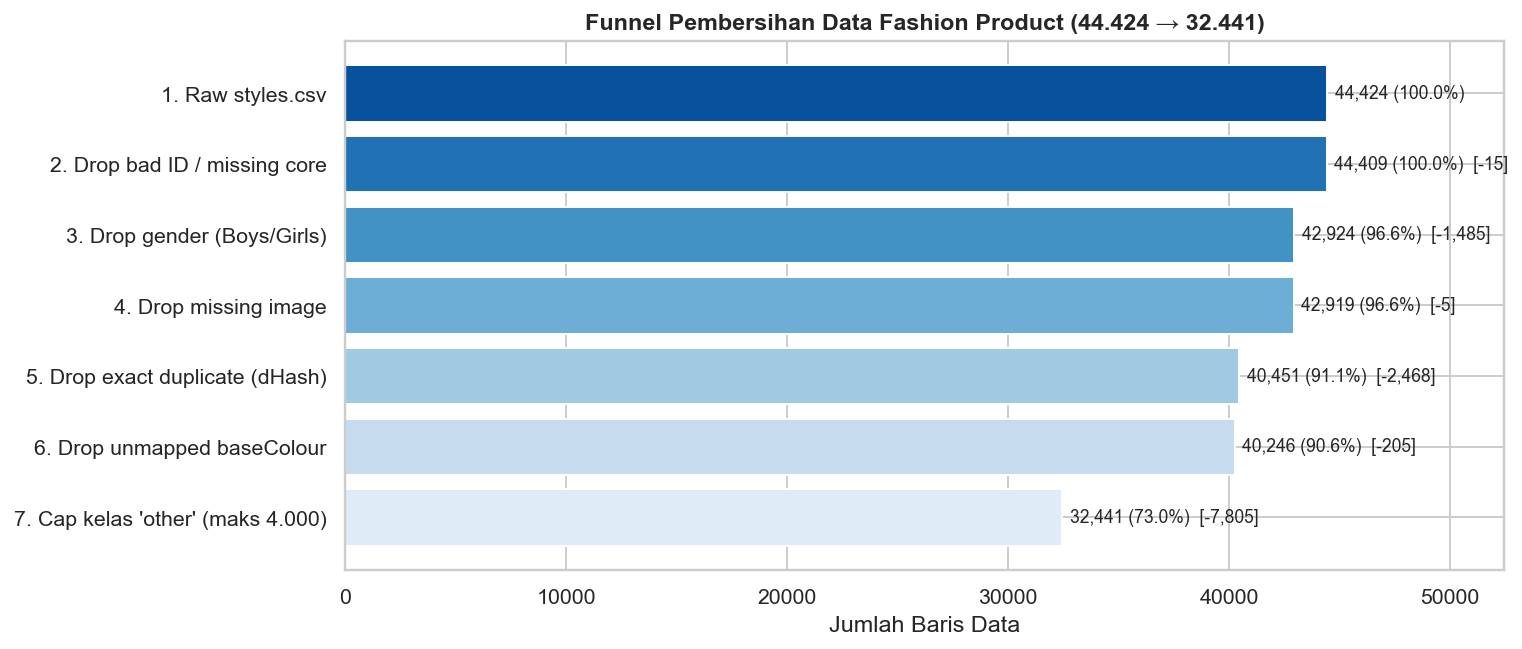

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/prep_cleaning_funnel.png


In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ML_DIR = Path.cwd()
if not (ML_DIR / "config_utils.py").exists() and (ML_DIR / "ml" / "config_utils.py").exists():
    ML_DIR = ML_DIR / "ml"
os.chdir(ML_DIR)
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config_utils as cu

sns.set_theme(style="whitegrid", context="notebook")
PLOT_DIR = cu.ensure_dir(cu.artifact_dir() / "plots")

report = json.loads((cu.artifact_dir() / "fashion_prepare_report.json").read_text(encoding="utf-8"))
index_df = pd.read_csv(cu.fashion_processed_dir() / "fashion_index.csv")
st = report["clean_stats"]

raw_total = (
    report["rows_final"]
    + (st["other_before_cap"] - st["other_after_cap"])
    + st["drop_unmapped_colour"]
    + st["drop_exact_duplicate"]
    + st["drop_missing_image"]
    + st["drop_gender"]
    + st["drop_missing_core"]
    + st["drop_bad_id"]
)

stages = [
    ("1. Raw styles.csv", raw_total, 0),
    ("2. Drop bad ID / missing core", raw_total - st["drop_bad_id"] - st["drop_missing_core"], st["drop_bad_id"] + st["drop_missing_core"]),
    ("3. Drop gender (Boys/Girls)", raw_total - st["drop_bad_id"] - st["drop_missing_core"] - st["drop_gender"], st["drop_gender"]),
    ("4. Drop missing image", raw_total - st["drop_bad_id"] - st["drop_missing_core"] - st["drop_gender"] - st["drop_missing_image"], st["drop_missing_image"]),
    ("5. Drop exact duplicate (dHash)", raw_total - st["drop_bad_id"] - st["drop_missing_core"] - st["drop_gender"] - st["drop_missing_image"] - st["drop_exact_duplicate"], st["drop_exact_duplicate"]),
    ("6. Drop unmapped baseColour", report["rows_final"] + (st["other_before_cap"] - st["other_after_cap"]), st["drop_unmapped_colour"]),
    ("7. Cap kelas 'other' (maks 4.000)", report["rows_final"], st["other_before_cap"] - st["other_after_cap"]),
]
funnel_df = pd.DataFrame(stages, columns=["Tahap Cleaning", "Sisa Baris", "Baris Dibuang"])
funnel_df["Retensi (%)"] = (funnel_df["Sisa Baris"] / raw_total * 100).round(2)

print("=== Tabel Ringkasan Data Cleaning (Fashion Product) ===")
display(funnel_df)

fig, ax = plt.subplots(figsize=(11, 4.8), dpi=140)
y_pos = np.arange(len(funnel_df))
bars = ax.barh(y_pos, funnel_df["Sisa Baris"], color=sns.color_palette("Blues_r", len(funnel_df)))
ax.set_yticks(y_pos)
ax.set_yticklabels(funnel_df["Tahap Cleaning"])
ax.invert_yaxis()
ax.set_xlabel("Jumlah Baris Data")
ax.set_title("Funnel Pembersihan Data Fashion Product (44.424 → 32.441)", fontweight="bold")
ax.set_xlim(0, raw_total * 1.18)
for i, (rem, drop, pct) in enumerate(zip(funnel_df["Sisa Baris"], funnel_df["Baris Dibuang"], funnel_df["Retensi (%)"])):
    note = f"{rem:,} ({pct:.1f}%)" + (f"  [-{drop:,}]" if drop > 0 else "")
    ax.text(rem + 350, i, note, va="center", fontsize=9)

plt.tight_layout()
fig.savefig(PLOT_DIR / "prep_cleaning_funnel.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "prep_cleaning_funnel.png"))

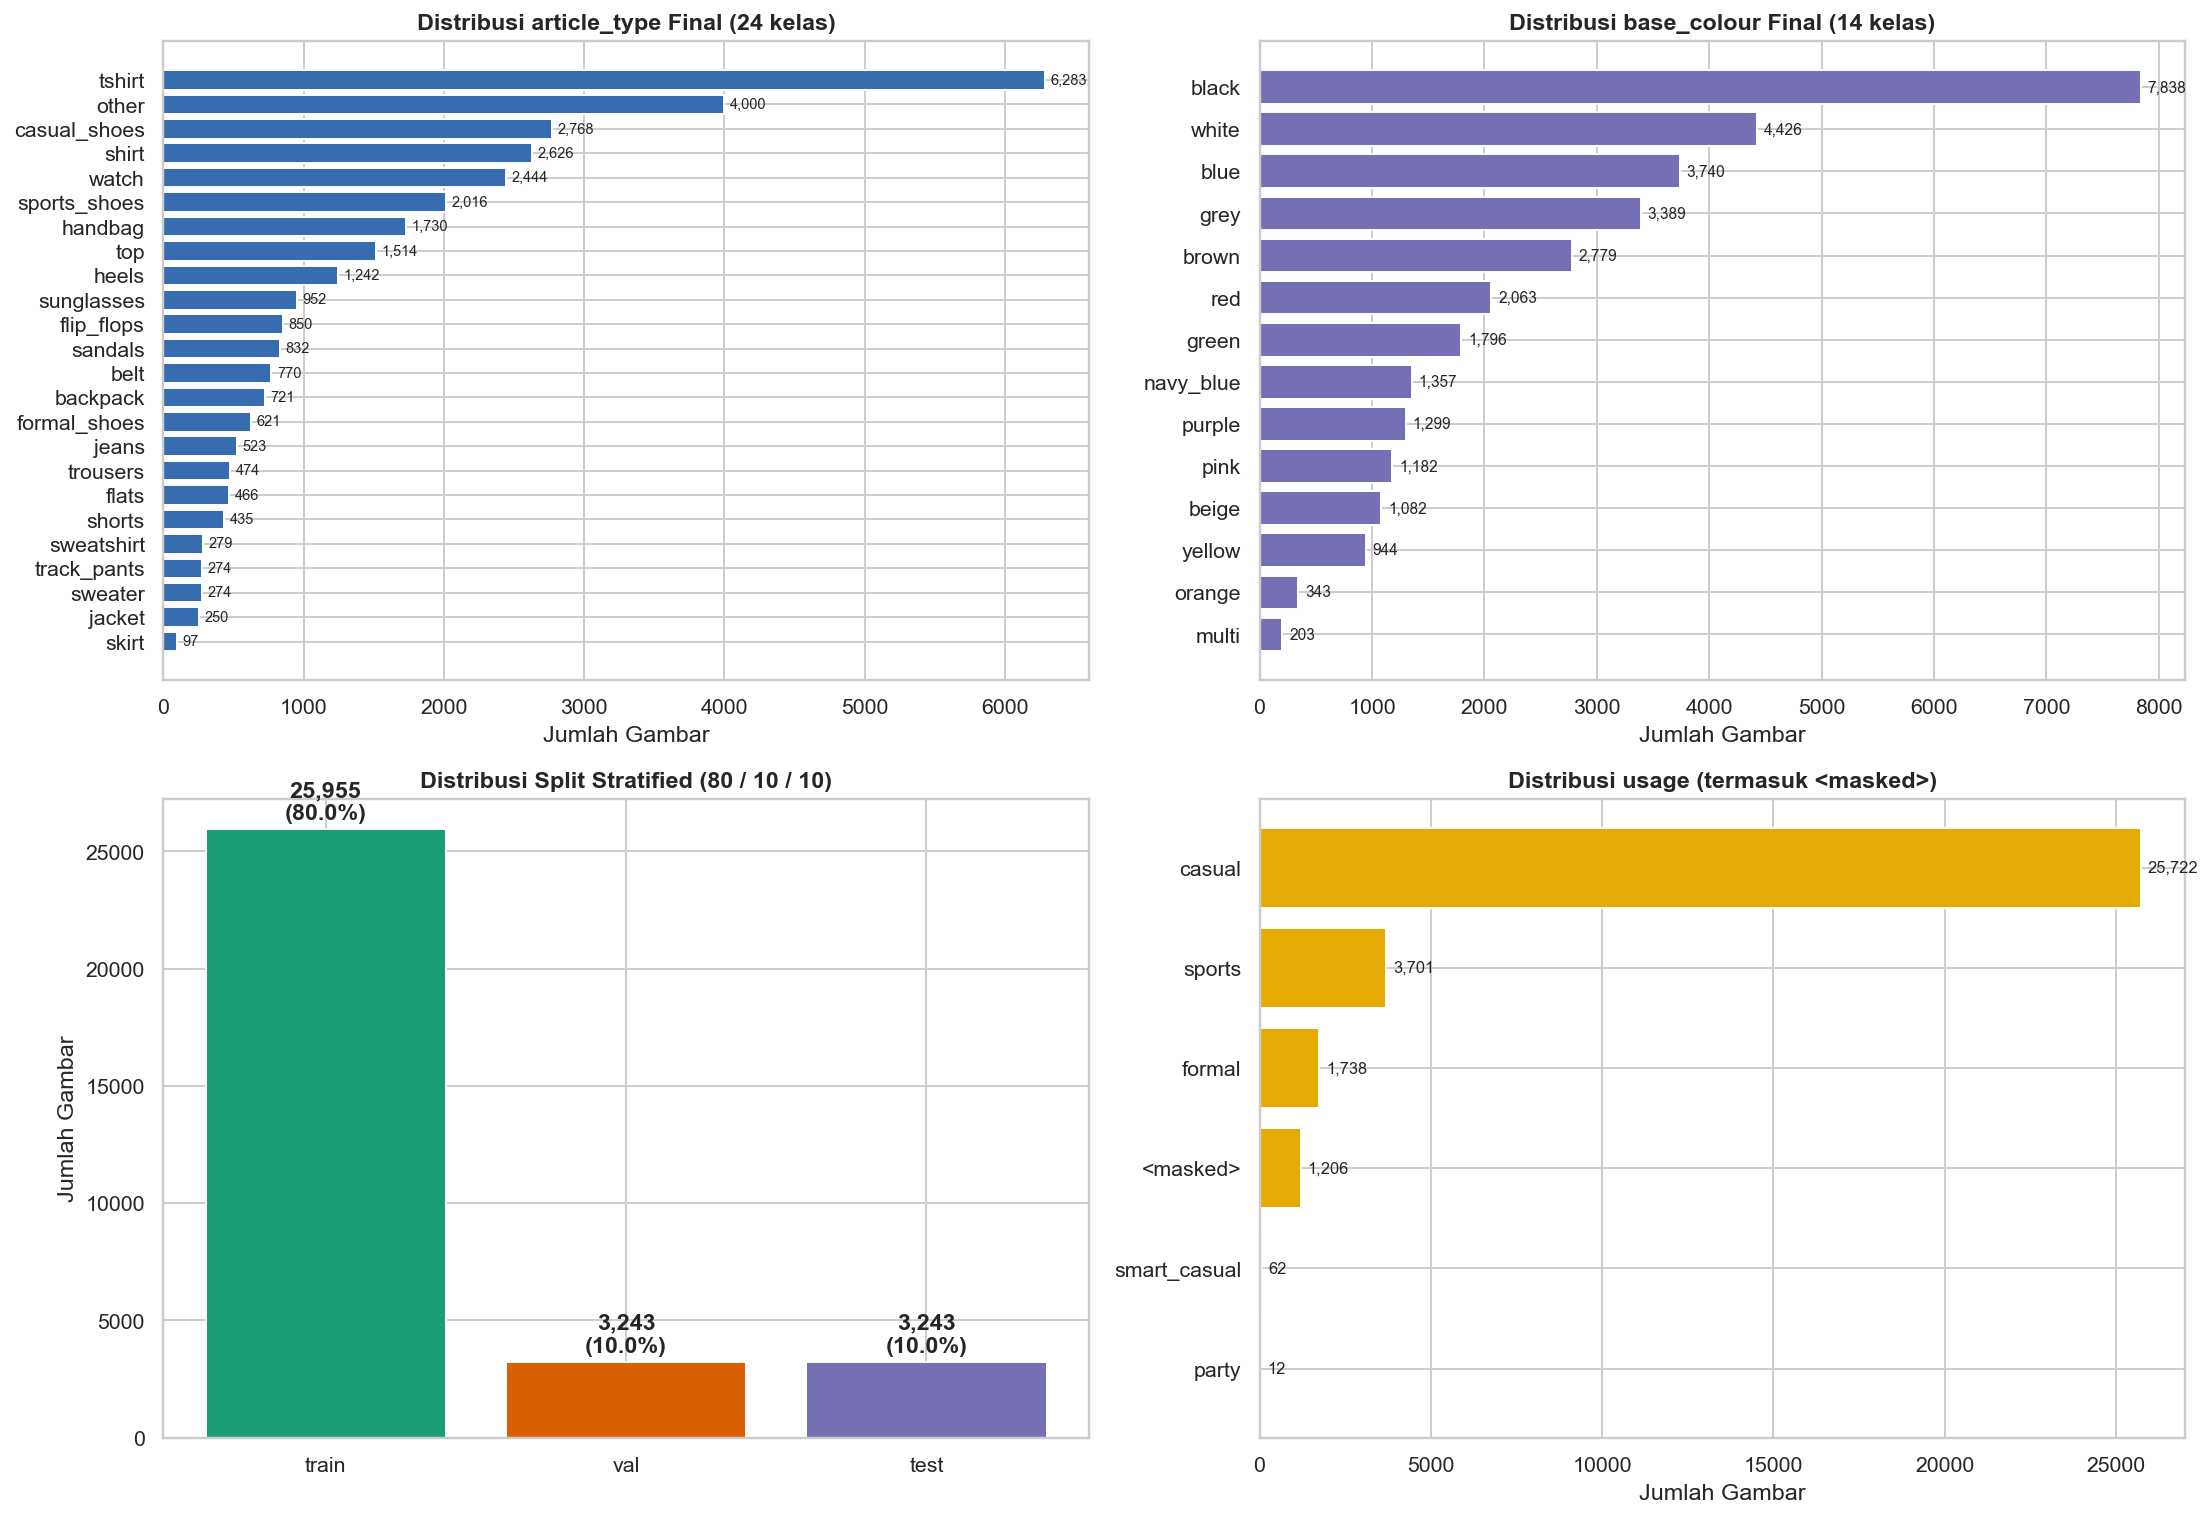

=== Distribusi Atribut Tambahan (Weather, Formality, Tone) ===


,Weather,Formality,Tone
<masked>,21,1206,0
cold,7110,0,0
cool,0,0,8192
formal,0,1738,0
hot,15196,0,0
mild,10114,0,0
neutral,0,0,15856
non_formal,0,29423,0
semi_formal,0,74,0
warm,0,0,8393


Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/prep_label_splits.png


In [2]:
# Distribusi Label Final & Verifikasi Split 80/10/10
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=140)

# 1. article_type (24 kelas)
art_s = pd.Series(report["article_counts"]).sort_values(ascending=True)
axes[0, 0].barh(art_s.index, art_s.values, color="#386cb0")
axes[0, 0].set_title(f"Distribusi article_type Final ({len(art_s)} kelas)", fontweight="bold")
axes[0, 0].set_xlabel("Jumlah Gambar")
for i, v in enumerate(art_s.values):
    axes[0, 0].text(v + 40, i, f"{v:,}", va="center", fontsize=7.5)

# 2. base_colour (14 kelas)
col_s = pd.Series(report["colour_counts"]).sort_values(ascending=True)
axes[0, 1].barh(col_s.index, col_s.values, color="#7570b3")
axes[0, 1].set_title(f"Distribusi base_colour Final ({len(col_s)} kelas)", fontweight="bold")
axes[0, 1].set_xlabel("Jumlah Gambar")
for i, v in enumerate(col_s.values):
    axes[0, 1].text(v + 60, i, f"{v:,}", va="center", fontsize=8)

# 3. Split 80/10/10 + usage & weather
split_order = ["train", "val", "test"]
split_vals = [report["split_sizes"][s] for s in split_order]
bars = axes[1, 0].bar(split_order, split_vals, color=["#1b9e77", "#d95f02", "#7570b3"])
axes[1, 0].set_title("Distribusi Split Stratified (80 / 10 / 10)", fontweight="bold")
axes[1, 0].set_ylabel("Jumlah Gambar")
for bar, v in zip(bars, split_vals):
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, v + 400, f"{v:,}\n({v/report['rows_final']*100:.1f}%)", ha="center", fontweight="bold")

# 4. Distribusi usage & weather
usage_s = pd.Series(report["usage_counts"]).sort_values(ascending=True)
axes[1, 1].barh(usage_s.index, usage_s.values, color="#e6ab02")
axes[1, 1].set_title("Distribusi usage (termasuk <masked>)", fontweight="bold")
axes[1, 1].set_xlabel("Jumlah Gambar")
for i, v in enumerate(usage_s.values):
    axes[1, 1].text(v + 200, i, f"{v:,}", va="center", fontsize=8.5)

plt.tight_layout()
fig.savefig(PLOT_DIR / "prep_label_splits.png", dpi=160, bbox_inches="tight")
plt.show()

# Tabel ringkasan split per weather & tone
print("=== Distribusi Atribut Tambahan (Weather, Formality, Tone) ===")
extra_df = pd.DataFrame({
    "Weather": pd.Series(report["weather_counts"]),
    "Formality": pd.Series(report["formality_counts"]),
    "Tone": pd.Series(report["tone_counts"]),
}).fillna(0).astype(int)
display(extra_df)
print("Saved:", cu.to_posix(PLOT_DIR / "prep_label_splits.png"))

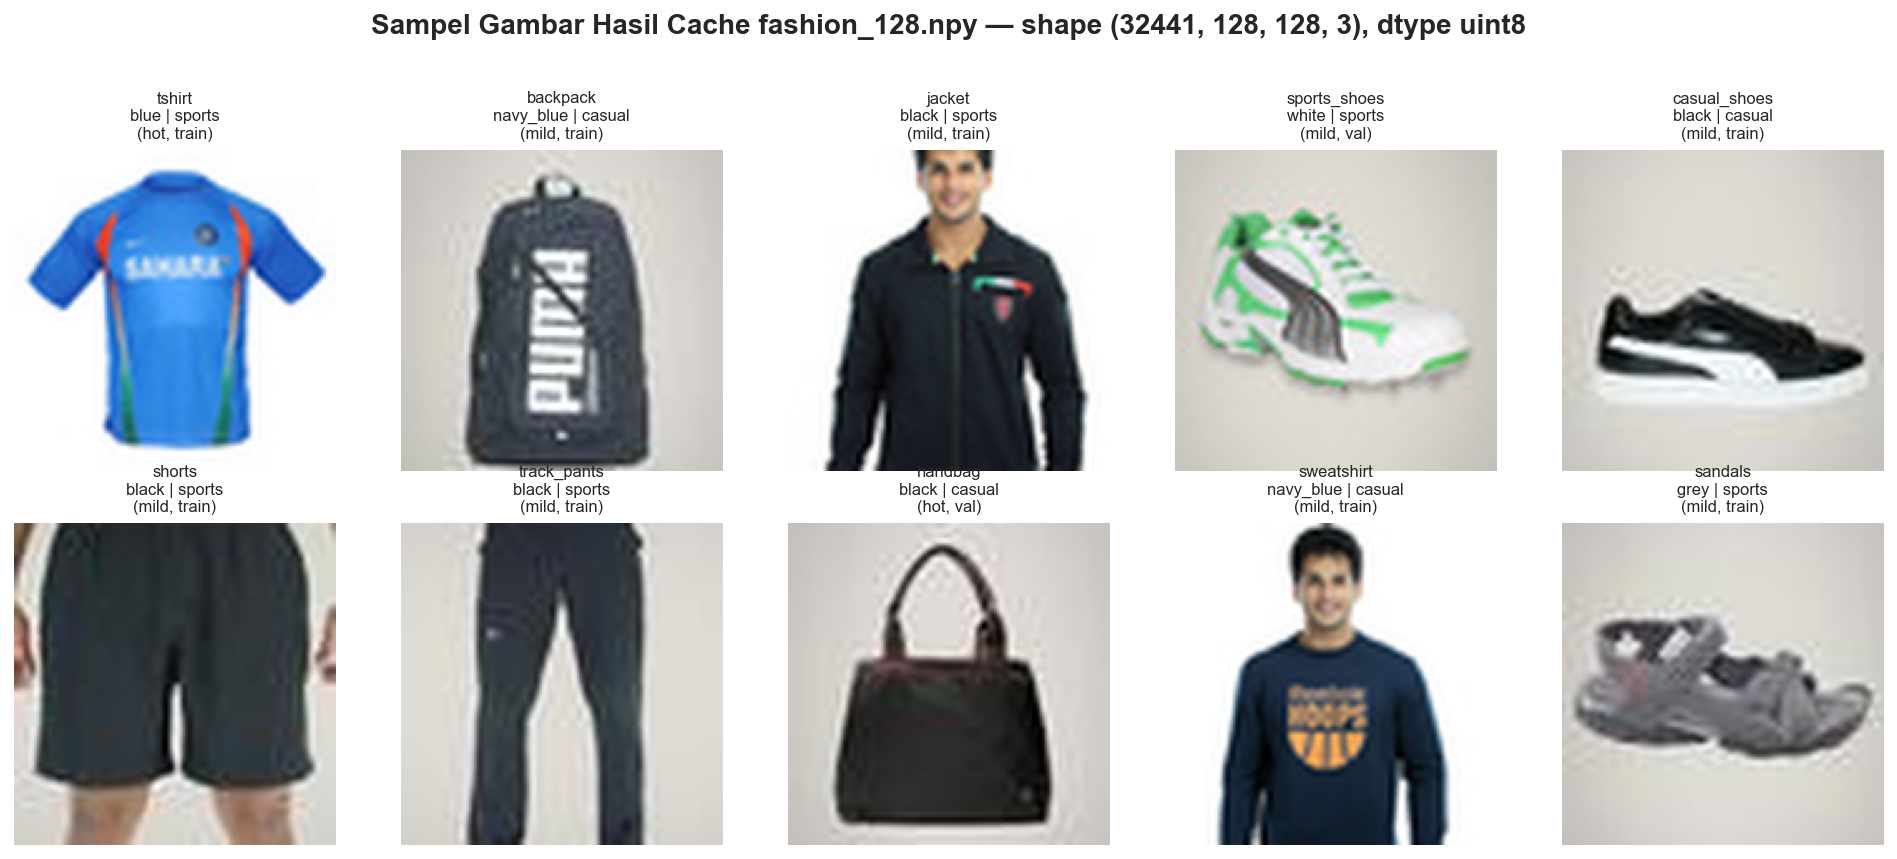

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/prep_sample_images.png


In [3]:
# Sampel Visual Gambar Hasil Preprocessing Cache (128x128 RGB uint8)
images = np.load(cu.fashion_processed_dir() / "fashion_128.npy", mmap_mode="r")
sample_df = index_df[index_df["article_type"] != "other"].groupby("article_type", group_keys=False).head(1).head(10).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(14, 6), dpi=140)
for ax, row in zip(axes.flat, sample_df.itertuples(index=False)):
    ax.imshow(images[int(row.npy_index)])
    usage_txt = row.usage if pd.notna(row.usage) and str(row.usage) else "<masked>"
    ax.set_title(f"{row.article_type}\n{row.base_colour} | {usage_txt}\n({row.weather}, {row.split})", fontsize=8.5)
    ax.axis("off")

plt.suptitle(f"Sampel Gambar Hasil Cache fashion_128.npy — shape {images.shape}, dtype {images.dtype}", fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(PLOT_DIR / "prep_sample_images.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "prep_sample_images.png"))